# 06 · Report experiments for the final model
**Report sections:** Training data size (Q2), Generalization and error analysis (Q4.1-Q4.3)

The final model is the one behind the selected Kaggle submission (public 0.963), rebuilt by
`make_submission.py`: a classifier (logistic regression + bagged trees on 87 language-model and repetition features)
rank-blended with Allen's `robust_svm_tuned` + blank-line boost, classifier weight 0.8.
Everything here uses the shared split (8,000 training rows / 2,000 validation rows, seed 42).

In [1]:
# --- setup: make `src/` and this folder importable from anywhere ---
import sys, re, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks" / "joling"))
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.config import SEED, set_seed, RESULTS_DIR
from src.data import get_split
from src.models import make_model
from src.features import has_blank_line_breaks
from src.evaluate import auroc, predict_proba1, savefig

from domain_eval import TopicDomains
from kind_eval import AIKinds
from lm_features import FEATURES, load_cached
from repetition_features import RP_FEATURES, WORD_FEATURES, load_cached as load_repetition
from lm_model import SMOL_FEATURES, lm_linear_plus_trees, blend
from plots import plot_learning_curve

set_seed(SEED)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)

train_df, val_df = get_split()
y_tr, y_va = train_df["label"].to_numpy(), val_df["label"].to_numpy()
COLUMNS = FEATURES + RP_FEATURES + WORD_FEATURES + SMOL_FEATURES
W = float(pd.read_csv(RESULTS_DIR / "joling_blend_weights_05.csv").sort_values("mean_of_both").iloc[-1]["lm_weight"])
print("classifier weight in the blend:", W)


def blank_push(p, texts, push=0.1):
    b = np.array([has_blank_line_breaks(t) for t in texts], dtype=float)
    return (np.asarray(p) + push * b) / (1 + push)


def fit_final(rows: pd.DataFrame):
    # The final pipeline, trained on the given rows. Returns a function texts -> (svm score, classifier score, blend).
    clf = lm_linear_plus_trees(columns=COLUMNS).fit(rows["text"], rows["label"])
    svm = make_model("robust_svm_tuned").fit(rows["text"], rows["label"])

    def score(texts):
        s = blank_push(predict_proba1(svm, texts), texts)
        c = predict_proba1(clf, texts)
        return s, c, blend(s, c, W)
    return score

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)
split: train=8000 (AI=0.500)  val=2000 (AI=0.500)  quick=False clean=True
classifier weight in the blend: 0.8


## Q2 · Effect of training-set size
The final configuration (same features, same hyperparameters, same blend weight) trained on 500, 1,000, 2,000, 5,000
and 8,000 rows. The subsets are nested and stratified: each smaller set is a random half-or-so of the next larger one,
drawn once with seed 42. The validation set never changes. "Training AUROC" is measured on the rows the model was
trained on.

In [3]:
SIZES = [500, 1000, 2000, 5000, 8000]
subset = train_df
subsets = {8000: train_df}
for n in SIZES[-2::-1]:                               # 5000, 2000, 1000, 500: each drawn from the previous one
    subset, _ = train_test_split(subset, train_size=n, stratify=subset["label"], random_state=SEED)
    subsets[n] = subset

rows, scorers = [], {}
for n in SIZES:
    t0 = time.time()
    part = subsets[n].reset_index(drop=True)
    score = fit_final(part)
    scorers[n] = score
    s_tr, c_tr, b_tr = score(part["text"])
    s_va, c_va, b_va = score(val_df["text"])
    rows.append({"training_rows": n, "train_auroc": auroc(part["label"], b_tr), "val_auroc": auroc(y_va, b_va),
                 "svm_val": auroc(y_va, s_va), "classifier_val": auroc(y_va, c_va),
                 "svm_train": auroc(part["label"], s_tr), "classifier_train": auroc(part["label"], c_tr),
                 "seconds": round(time.time() - t0, 1)})
    print(rows[-1])
curve = pd.DataFrame(rows)
curve["gap"] = curve["train_auroc"] - curve["val_auroc"]
curve.to_csv(RESULTS_DIR / "joling_report_learning_curve.csv", index=False)
curve.round(4)

{'training_rows': 500, 'train_auroc': 1.0, 'val_auroc': 0.9936450000000001, 'svm_val': 0.9581559999999999, 'classifier_val': 0.989856, 'svm_train': 1.0, 'classifier_train': 0.999872, 'seconds': 11.3}


{'training_rows': 1000, 'train_auroc': 0.99998, 'val_auroc': 0.9952300000000001, 'svm_val': 0.970464, 'classifier_val': 0.991035, 'svm_train': 1.0, 'classifier_train': 0.9995799999999999, 'seconds': 11.7}


{'training_rows': 2000, 'train_auroc': 0.999952, 'val_auroc': 0.9958865, 'svm_val': 0.982484, 'classifier_val': 0.9918790000000001, 'svm_train': 1.0, 'classifier_train': 0.999311, 'seconds': 17.3}


{'training_rows': 5000, 'train_auroc': 0.99980128, 'val_auroc': 0.9968105, 'svm_val': 0.9871300000000001, 'classifier_val': 0.993052, 'svm_train': 1.0, 'classifier_train': 0.9980640000000001, 'seconds': 35.2}


{'training_rows': 8000, 'train_auroc': 0.999560625, 'val_auroc': 0.997107, 'svm_val': 0.990531, 'classifier_val': 0.993579, 'svm_train': 1.0, 'classifier_train': 0.997458, 'seconds': 54.7}


,training_rows,train_auroc,val_auroc,svm_val,classifier_val,svm_train,classifier_train,seconds,gap
0,500,1.0000,0.9936,0.9582,0.9899,1.0,0.9999,11.3,0.0064
1,1000,1.0000,0.9952,0.9705,0.9910,1.0,0.9996,11.7,0.0047
2,2000,1.0000,0.9959,0.9825,0.9919,1.0,0.9993,17.3,0.0041
3,5000,0.9998,0.9968,0.9871,0.9931,1.0,0.9981,35.2,0.0030
4,8000,0.9996,0.9971,0.9905,0.9936,1.0,0.9975,54.7,0.0025


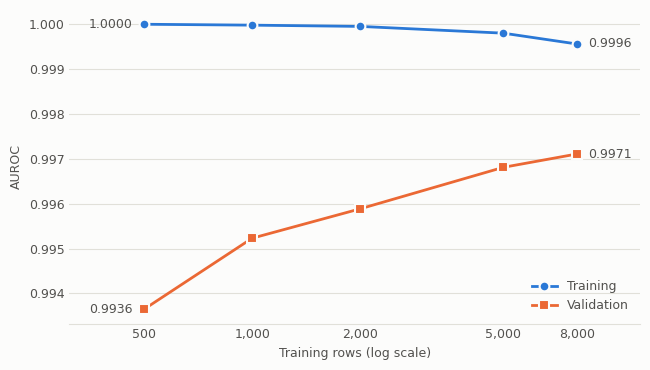

In [4]:
fig = plot_learning_curve(curve["training_rows"], curve["train_auroc"], curve["val_auroc"])
savefig(fig, "joling_learning_curve");

## Q4.1 · Training versus validation AUROC of the final model
Trained on the 8,000 training rows. The interval is a bootstrap over validation rows (1,000 resamples).
The unseen-domain and unseen-kind numbers are copied from notebook `05`; the Kaggle score is the public leaderboard.

In [5]:
score = scorers[8000]
s_tr, c_tr, b_tr = score(train_df["text"])
s_va, c_va, b_va = score(val_df["text"])
rng = np.random.default_rng(SEED)
boot = [auroc(y_va[i], b_va[i]) for i in (rng.integers(0, len(y_va), len(y_va)) for _ in range(1000))]
b05 = pd.read_csv(RESULTS_DIR / "joling_blend_05.csv").iloc[-1]
q41 = pd.DataFrame([
    {"model": "final blend", "train_auroc": auroc(y_tr, b_tr), "val_auroc": auroc(y_va, b_va),
     "val_ci_low": np.percentile(boot, 2.5), "val_ci_high": np.percentile(boot, 97.5),
     "unseen_domain": b05["unseen_domain"], "unseen_ai_kind": b05["unseen_ai_kind"], "kaggle_public": 0.96311},
    {"model": "classifier alone", "train_auroc": auroc(y_tr, c_tr), "val_auroc": auroc(y_va, c_va), "kaggle_public": 0.95508},
    {"model": "svm + blank-line boost alone", "train_auroc": auroc(y_tr, s_tr), "val_auroc": auroc(y_va, s_va), "kaggle_public": 0.91328},
])
q41["train_minus_val"] = q41["train_auroc"] - q41["val_auroc"]
q41["val_minus_kaggle"] = q41["val_auroc"] - q41["kaggle_public"]
q41.to_csv(RESULTS_DIR / "joling_report_q41.csv", index=False)
q41.round(4)

,model,train_auroc,val_auroc,val_ci_low,val_ci_high,unseen_domain,unseen_ai_kind,kaggle_public,train_minus_val,val_minus_kaggle
0,final blend,0.9996,0.9971,0.9956,0.9984,0.9933,0.992,0.9631,0.0025,0.0340
1,classifier alone,0.9975,0.9936,NaN,NaN,NaN,NaN,0.9551,0.0039,0.0385
2,svm + blank-line boost alone,1.0000,0.9905,NaN,NaN,NaN,NaN,0.9133,0.0095,0.0773


## Q4.2 · Performance by subgroup
Three length bins around the ~210-word average (shorter texts give any detector less evidence), and, because they
are the shifts the hidden test set is said to contain, the topic domains and AI kinds from notebooks `01` and `04`.
For AI kinds the group is "AI texts of that kind against all human validation texts".

In [6]:
words = val_df["text"].str.split().str.len().to_numpy()
length_bin = np.where(words < 150, "under 150 words", np.where(words <= 250, "150-250 words", "over 250 words"))
rows = [{"grouping": "length", "group": g, "count": int((length_bin == g).sum()), "ai_share": float(y_va[length_bin == g].mean()),
         "val_auroc": auroc(y_va[length_bin == g], b_va[length_bin == g])} for g in ["under 150 words", "150-250 words", "over 250 words"]]

domains = TopicDomains(k=8).fit(train_df["text"])
dom_va = domains.predict(val_df["text"])
for d in range(domains.k):
    m = dom_va == d
    rows.append({"grouping": "topic domain", "group": domains.names_[d], "count": int(m.sum()), "ai_share": float(y_va[m].mean()),
                 "val_auroc": auroc(y_va[m], b_va[m])})

gpt2 = load_cached().join(load_repetition().drop(columns="file"))
KF = FEATURES + RP_FEATURES
kinds = AIKinds(k=4).fit(gpt2.loc[train_df["id"][y_tr == 1], KF])
kind_va = kinds.assign(gpt2.loc[val_df["id"], KF], y_va)
KIND_NAMES = {0: "kind 0: close to human on every feature", 1: "kind 1: very predictable", 2: "kind 2: avoids repetition", 3: "kind 3: ordinary smooth AI"}
for c in range(kinds.k):
    m = (kind_va == c) | (y_va == 0)
    rows.append({"grouping": "AI kind vs all humans", "group": KIND_NAMES[c], "count": int((kind_va == c).sum()),
                 "ai_share": np.nan, "val_auroc": auroc(y_va[m], b_va[m])})
q42 = pd.DataFrame(rows)
q42.to_csv(RESULTS_DIR / "joling_report_q42.csv", index=False)
q42.round(4)

,grouping,group,count,ai_share,val_auroc
0,length,under 150 words,404,0.6287,0.9976
1,length,150-250 words,1065,0.4131,0.9968
2,length,over 250 words,531,0.5763,0.9976
3,topic domain,"d0: ve, like, just",394,0.5178,0.9997
4,topic domain,"d1: said, year, company",357,0.5014,0.9941
5,topic domain,"d2: properties, study, quantum",193,0.4663,0.9981
6,topic domain,"d3: pepper, cup, chopped",204,0.5147,0.9986
7,topic domain,"d4: film, movie, br",146,0.5479,0.9987
8,topic domain,"d5: segmentation, image, images",231,0.4545,0.9987
9,topic domain,"d6: sugar, cup, flour",188,0.5000,0.9896


## Q4.3 · False positives and false negatives
The blend score is a rank average between 0 and 1, and the validation set is half human, half AI, so we use 0.5 as
the decision threshold. **False positive** = human text scored above 0.5; **false negative** = AI text scored below 0.5.
We list the ten most confident errors of each type with the facts that might explain them. The text preview is for
our own reading; the report only needs IDs, scores and a short hypothesis.

In [7]:
smol = pd.read_csv(RESULTS_DIR / "joling_onepass_features_SmolLM2-360M.csv").set_index("id")
err = pd.DataFrame({
    "id": val_df["id"].to_numpy(), "label": y_va, "p_blend": b_va, "p_classifier": c_va, "p_svm": s_va,
    "words": words, "domain": [domains.names_[d] for d in dom_va],
    "ai_kind": [KIND_NAMES[k].split(":")[0] if k >= 0 else "human" for k in kind_va],
    "line_breaks": val_df["text"].str.count("\n").to_numpy(),
    "ll_std_smol": smol.loc[val_df["id"], "ll_std"].to_numpy(), "top1_smol": smol.loc[val_df["id"], "top1"].to_numpy(),
    "rp_deficit_smol": smol.loc[val_df["id"], "rp_deficit"].to_numpy(),
    "preview": val_df["text"].map(lambda t: re.sub(r"\s+", " ", t)[:220]).to_numpy(),
})
THRESHOLD = 0.5
fp = err[(err.label == 0) & (err.p_blend > THRESHOLD)].sort_values("p_blend", ascending=False)
fn = err[(err.label == 1) & (err.p_blend < THRESHOLD)].sort_values("p_blend")
print(f"threshold {THRESHOLD}: {len(fp)} false positives out of {(y_va == 0).sum()} human texts, "
      f"{len(fn)} false negatives out of {(y_va == 1).sum()} AI texts")
print("typical human validation text:  ll_std", round(err[err.label == 0].ll_std_smol.median(), 2), " top1", round(err[err.label == 0].top1_smol.median(), 2),
      " rp_deficit", round(err[err.label == 0].rp_deficit_smol.median(), 3))
print("typical AI validation text:     ll_std", round(err[err.label == 1].ll_std_smol.median(), 2), " top1", round(err[err.label == 1].top1_smol.median(), 2),
      " rp_deficit", round(err[err.label == 1].rp_deficit_smol.median(), 3))
errors = pd.concat([fp.head(10).assign(error="FP"), fn.head(10).assign(error="FN")])
errors.to_csv(RESULTS_DIR / "joling_report_q43_errors.csv", index=False)
cols = ["error", "id", "p_blend", "p_classifier", "p_svm", "words", "domain", "ai_kind", "line_breaks", "ll_std_smol", "top1_smol", "rp_deficit_smol"]
errors[cols].round(3)

threshold 0.5: 9 false positives out of 1000 human texts, 30 false negatives out of 1000 AI texts
typical human validation text:  ll_std 2.64  top1 0.45  rp_deficit -0.012
typical AI validation text:     ll_std 2.03  top1 0.56  rp_deficit 0.005


,error,id,p_blend,p_classifier,p_svm,words,domain,ai_kind,line_breaks,ll_std_smol,top1_smol,rp_deficit_smol
642,FP,3326,0.530,0.819,0.404,114,"d4: film, movie, br",human,0,2.485,0.469,-0.008
809,FP,4062,0.520,0.526,0.475,193,"d1: said, year, company",human,1,2.609,0.648,-0.003
973,FP,4947,0.515,0.387,0.490,205,"d1: said, year, company",human,13,2.543,0.582,-0.003
985,FP,5027,0.514,0.532,0.441,147,"d2: properties, study, quantum",human,14,2.716,0.473,-0.012
1006,FP,5141,0.514,0.659,0.399,230,"d2: properties, study, quantum",human,21,2.226,0.658,-0.016
203,FP,1131,0.513,0.505,0.447,181,"d1: said, year, company",human,2,2.142,0.428,-0.023
1952,FP,9765,0.510,0.391,0.463,284,"d1: said, year, company",human,2,2.281,0.486,0.015
1085,FP,5516,0.508,0.689,0.371,318,"d1: said, year, company",human,4,2.053,0.514,-0.005
1271,FP,6366,0.501,0.565,0.378,171,"d7: born, university, career",human,1,2.461,0.602,-0.025
906,FN,4549,0.271,0.009,0.450,220,"d6: sugar, cup, flour",kind 3,17,2.459,0.564,-0.006


In [8]:
for _, r in errors.iterrows():
    print(f"[{r.error} id {r.id} p={r.p_blend:.2f}] {r.preview}\n")

[FP id 3326 p=0.53] The Academy Award winning war epic Braveheart is an extraordinary film that set a new bar for the genre. The story follows a Scottish peasant named William Wallace who's pushed into leading a rebellion against the tyrann

[FP id 4062 p=0.52] "Free Yourself" is a song by American singer Fantasia. It was written by rapper Missy Elliott, Craig Brockman, and Nisan Stewart for her debut album of the same name (2004), while production was helmed by Elliott, with B

[FP id 4947 p=0.51] Lorada is a 1995 album recorded by French singer Johnny Hallyday. It was released on June 20, 1995, and achieved success in France and Belgium (Wallonia), where, however, it failed to top the charts, being blocked by Mic

[FP id 5027 p=0.51] Under the actions of internal pressure and electric voltage, a spherical dielectric elastomer balloon usually keeps a sphere during its deformation, which has also been assumed in many previous studies. In this article, 

[FP id 5141 p=0.51] A b-coloring

In [9]:
# Where do the errors fall? Share of all false positives / false negatives by domain and (for FN) by AI kind.
by_domain = pd.DataFrame({"false positives": fp["domain"].value_counts(), "false negatives": fn["domain"].value_counts(),
                          "validation texts": err["domain"].value_counts()}).fillna(0).astype(int)
by_kind = pd.DataFrame({"false negatives": fn["ai_kind"].value_counts(), "AI validation texts": err[err.label == 1]["ai_kind"].value_counts()}).fillna(0).astype(int)
by_kind["miss rate"] = (by_kind["false negatives"] / by_kind["AI validation texts"]).round(3)
by_domain.to_csv(RESULTS_DIR / "joling_report_q43_by_domain.csv")
by_kind.to_csv(RESULTS_DIR / "joling_report_q43_by_kind.csv")
display(by_domain)
display(by_kind)
print("errors where the two models disagreed (one was right):  FP", int(((fp.p_classifier > 0.5) != (fp.p_svm > 0.5)).sum()), "of", len(fp),
      "| FN", int(((fn.p_classifier > 0.5) != (fn.p_svm > 0.5)).sum()), "of", len(fn))

,false positives,false negatives,validation texts
domain,,,
"d0: ve, like, just",0,2,394
"d1: said, year, company",5,7,357
"d2: properties, study, quantum",2,2,193
"d3: pepper, cup, chopped",0,5,204
"d4: film, movie, br",1,1,146
"d5: segmentation, image, images",0,4,231
"d6: sugar, cup, flour",0,4,188
"d7: born, university, career",1,5,287


,false negatives,AI validation texts,miss rate
ai_kind,,,
kind 0,22,277,0.079
kind 1,0,61,0.000
kind 2,0,162,0.000
kind 3,8,500,0.016


errors where the two models disagreed (one was right):  FP 7 of 9 | FN 10 of 30
